In [1]:

import sys
from pathlib import Path

print("Python executable:", sys.executable)
print("Project directory:", Path.cwd())


Python executable: c:\Users\Cynthia\AppData\Local\Programs\Python\Python312\python.exe
Project directory: c:\Users\Cynthia\OneDrive - Victory Farms Ltd\Desktop\Tilapia Eggs CNN 2\notebooks


In [2]:
import os
import hashlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile, UnidentifiedImageError
from IPython.display import display

print("Libraries imported successfully.")


ModuleNotFoundError: No module named 'numpy'

In [3]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\Cynthia\AppData\Local\Programs\Python\Python312\python.exe
Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [1]:
import os
import hashlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile, UnidentifiedImageError
from IPython.display import display

print("Libraries imported successfully.")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Libraries imported successfully.
NumPy version: 2.5.4
Pandas version: 3.0.6


In [3]:

DATASET_DIR = Path("../dataset").resolve()

CLASSES = ["Healthy", "Unhealthy"]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

print("Dataset path:", DATASET_DIR)
print("Dataset folder exists:", DATASET_DIR.exists())

for class_name in CLASSES:
    class_dir = DATASET_DIR / class_name
    print(f"{class_name} folder exists:", class_dir.exists())


Dataset path: C:\Users\Cynthia\OneDrive - Victory Farms Ltd\Desktop\Tilapia Eggs CNN 2\dataset
Dataset folder exists: True
Healthy folder exists: True
Unhealthy folder exists: True


In [4]:

class_counts = {}

for class_name in CLASSES:
    class_dir = DATASET_DIR / class_name

    if class_dir.exists():
        files = [
            f for f in class_dir.rglob("*")
            if f.is_file()
            and f.suffix.lower() in IMAGE_EXTENSIONS
        ]
        class_counts[class_name] = len(files)
    else:
        class_counts[class_name] = 0

counts_df = pd.DataFrame({
    "Class": list(class_counts.keys()),
    "Number of Images": list(class_counts.values())
})

display(counts_df)

print("Total images:", sum(class_counts.values()))


,Class,Number of Images
0,Healthy,40
1,Unhealthy,40


Total images: 80


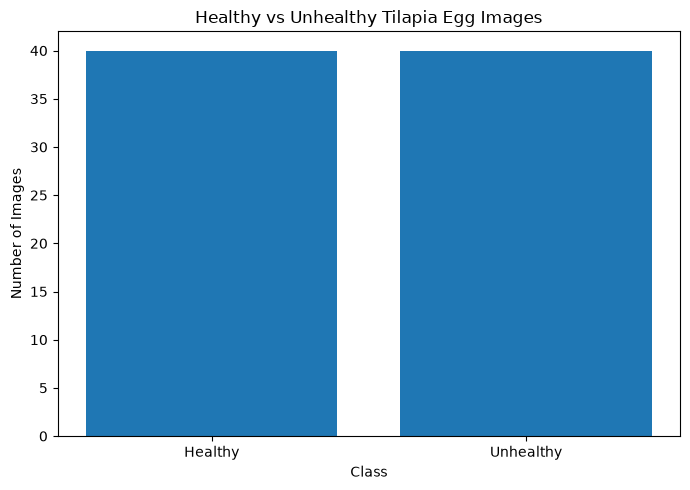

In [5]:

plt.figure(figsize=(7, 5))

plt.bar(
    counts_df["Class"],
    counts_df["Number of Images"]
)

plt.title("Healthy vs Unhealthy Tilapia Egg Images")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()


In [6]:

image_records = []

for class_name in CLASSES:
    class_dir = DATASET_DIR / class_name

    if not class_dir.exists():
        continue

    for file_path in class_dir.rglob("*"):
        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(file_path) as img:
                image_records.append({
                    "class": class_name,
                    "filename": file_path.name,
                    "path": str(file_path),
                    "width": img.width,
                    "height": img.height,
                    "format": img.format,
                    "mode": img.mode,
                    "size_kb": round(
                        file_path.stat().st_size / 1024, 2
                    )
                })

        except (OSError, UnidentifiedImageError) as error:
            print(f"Unreadable: {file_path} — {error}")

image_df = pd.DataFrame(image_records)

if not image_df.empty:
    display(image_df.head(10))

    print("Dimension statistics:")
    display(image_df[["width", "height"]].describe())

    print("Image formats:")
    display(image_df["format"].value_counts())

    print("Colour modes:")
    display(image_df["mode"].value_counts())


,class,filename,path,width,height,format,mode,size_kb
0,Healthy,healthy_tilapia_egg_001.jpg,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,126,114,JPEG,RGB,12.27
1,Healthy,healthy_tilapia_egg_002.jpg,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,114,JPEG,RGB,13.20
2,Healthy,healthy_tilapia_egg_003.jpg,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,114,JPEG,RGB,13.21
3,Healthy,healthy_tilapia_egg_004.jpg,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,114,JPEG,RGB,12.20
4,Healthy,healthy_tilapia_egg_005.jpg,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,123,114,JPEG,RGB,12.44
5,Healthy,healthy_tilapia_egg_006.jpg,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,114,JPEG,RGB,12.38
6,Healthy,healthy_tilapia_egg_007.jpg,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,124,114,JPEG,RGB,11.95
7,Healthy,healthy_tilapia_egg_008.jpg,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,114,JPEG,RGB,12.64
8,Healthy,healthy_tilapia_egg_009.jpg,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,114,JPEG,RGB,11.59
9,Healthy,healthy_tilapia_egg_010.jpg,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,126,114,JPEG,RGB,11.42


Dimension statistics:


,width,height
count,80.000000,80.000000
mean,124.900000,125.375000
std,0.835903,10.660913
min,123.000000,114.000000
25%,125.000000,118.250000
50%,125.000000,124.000000
75%,125.000000,127.000000
max,126.000000,150.000000


Image formats:


format
JPEG    80
Name: count, dtype: int64

Colour modes:


mode
RGB    80
Name: count, dtype: int64

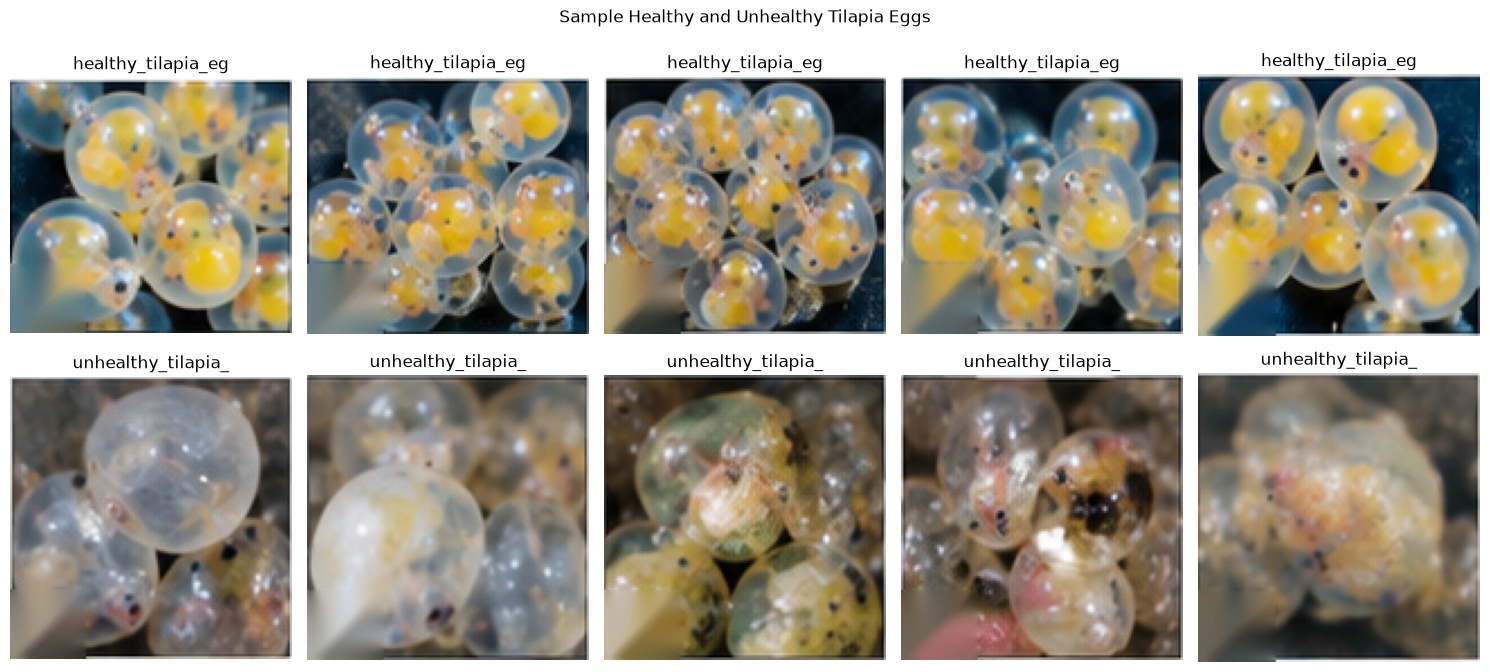

In [7]:

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for row, class_name in enumerate(CLASSES):
    class_dir = DATASET_DIR / class_name

    if not class_dir.exists():
        axes[row, 0].set_title(f"{class_name}: folder missing")
        for ax in axes[row]:
            ax.axis("off")
        continue

    files = [
        f for f in class_dir.rglob("*")
        if f.is_file()
        and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    shown = 0

    for file_path in files:
        try:
            with Image.open(file_path) as img:
                sample = img.convert("RGB").copy()

            axes[row, shown].imshow(sample)
            axes[row, shown].set_title(file_path.name[:18])
            axes[row, shown].axis("off")

            shown += 1
            if shown == 5:
                break

        except (OSError, UnidentifiedImageError):
            continue

    for col in range(shown, 5):
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(class_name, fontsize=12)

plt.suptitle("Sample Healthy and Unhealthy Tilapia Eggs")
plt.tight_layout()
plt.show()


In [8]:

corrupted_images = []

for class_name in CLASSES:
    class_dir = DATASET_DIR / class_name

    if not class_dir.exists():
        continue

    for file_path in class_dir.rglob("*"):
        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(file_path) as img:
                img.verify()

        except (OSError, UnidentifiedImageError, ValueError) as error:
            corrupted_images.append({
                "class": class_name,
                "path": str(file_path),
                "error": str(error)
            })

corrupted_df = pd.DataFrame(corrupted_images)

print("Corrupted or unreadable images:", len(corrupted_df))
display(corrupted_df)


Corrupted or unreadable images: 0


""


In [9]:

hash_records = []

for class_name in CLASSES:
    class_dir = DATASET_DIR / class_name

    if not class_dir.exists():
        continue

    for file_path in class_dir.rglob("*"):
        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            digest = hashlib.sha256(
                file_path.read_bytes()
            ).hexdigest()

            hash_records.append({
                "class": class_name,
                "path": str(file_path),
                "sha256": digest
            })

        except OSError as error:
            print(f"Could not read {file_path}: {error}")

hash_df = pd.DataFrame(hash_records)

if not hash_df.empty:
    duplicates_df = hash_df[
        hash_df.duplicated("sha256", keep=False)
    ].sort_values("sha256")

    print("Files involved in exact duplicates:",
          len(duplicates_df))
    display(duplicates_df)


Files involved in exact duplicates: 0


,class,path,sha256


In [10]:

import cv2

quality_records = []

for class_name in CLASSES:
    class_dir = DATASET_DIR / class_name

    if not class_dir.exists():
        continue

    for file_path in class_dir.rglob("*"):
        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        image = cv2.imread(str(file_path))

        if image is None:
            continue

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        sharpness = cv2.Laplacian(
            gray, cv2.CV_64F
        ).var()

        quality_records.append({
            "class": class_name,
            "path": str(file_path),
            "width": image.shape[1],
            "height": image.shape[0],
            "sharpness_score": sharpness
        })

quality_df = pd.DataFrame(quality_records)

if not quality_df.empty:
    display(
        quality_df.sort_values("sharpness_score").head(15)
    )


,class,path,width,height,sharpness_score
0,Healthy,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,126,114,940.071081
41,Unhealthy,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,126,942.199131
35,Healthy,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,122,989.459139
72,Unhealthy,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,150,1133.457601
42,Unhealthy,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,126,1187.294798
21,Healthy,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,116,1205.090507
77,Unhealthy,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,150,1216.308587
24,Healthy,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,123,116,1262.480922
75,Unhealthy,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,125,150,1286.650645
70,Unhealthy,C:\Users\Cynthia\OneDrive - Victory Farms Ltd\...,126,150,1339.236621


In [11]:

summary = {
    "Number of classes": len(CLASSES),
    "Classes containing images": sum(
        count > 0 for count in class_counts.values()
    ),
    "Total images": sum(class_counts.values()),
    "Readable images inspected": len(image_df),
    "Corrupted/unreadable images": len(corrupted_df),
    "Files involved in exact duplicates": (
        len(duplicates_df)
        if "duplicates_df" in globals()
        else 0
    )
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Metric", "Result"]
)

display(summary_df)


,Metric,Result
0,Number of classes,2
1,Classes containing images,2
2,Total images,80
3,Readable images inspected,80
4,Corrupted/unreadable images,0
5,Files involved in exact duplicates,0
